# Sensor Data Exploration

This notebook explores the aligned multimodal sensor data in `aligned_h5`.

Goals:
- inspect participant/task naming and HDF5 structure
- summarize recording durations and modality availability
- visualize gaze, hand keypoints, IMU, and depth signals
- check missing values and coordinate ranges before gaze-object / hand-object fusion

## Setup

Run this notebook with the `object_detection` conda environment, or any environment that has:

```bash
h5py pandas numpy matplotlib
```

In [1]:
from pathlib import Path
import math

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

DATASET_ROOT = Path("/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18")
ALIGNED_H5_ROOT = DATASET_ROOT / "aligned_h5"

PARTICIPANT_ID = "IA_4_H_02"
TASK_NAME = "Tasche_packen1"

h5_path = ALIGNED_H5_ROOT / PARTICIPANT_ID / f"{PARTICIPANT_ID}_{TASK_NAME}_aligned_dataset.h5"
h5_path

PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/aligned_h5/IA_4_H_02/IA_4_H_02_Tasche_packen1_aligned_dataset.h5')

In [2]:
assert h5_path.exists(), f"Missing file: {h5_path}"

with h5py.File(h5_path, "r") as f:
    print("Top-level groups:", list(f.keys()))
    print("Metadata keys:", list(f["metadata"].keys()))
    print("Number of modality groups:", len(f["modalities"]))
    print("Modality groups:")
    for name in f["modalities"].keys():
        print("  -", name)

Top-level groups: ['metadata', 'modalities']
Metadata keys: ['global_time_nanoseconds', 'global_time_seconds', 'sync_pulses']
Number of modality groups: 11
Modality groups:
  - eye_tracker__gaze
  - eye_tracker__imu
  - movella__DOT_D422CD008603
  - movella__DOT_D422CD008CC7
  - movella__DOT_D422CD009F54
  - movella__DOT_D422CD009F5B
  - movella__DOT_D422CD009F60
  - movella__DOT_D422CD00A220
  - movella__DOT_D422CD00A795
  - zed__depth
  - zed__skeleton__Body_69


## Helper Functions

In [3]:
def read_group_as_df(h5_file, group_path):
    """Read a flat HDF5 group into a DataFrame."""
    group = h5_file[group_path]
    data = {key: group[key][:] for key in group.keys() if isinstance(group[key], h5py.Dataset)}
    return pd.DataFrame(data)


def finite_ratio(values):
    arr = np.asarray(values)
    if arr.size == 0:
        return np.nan
    return np.isfinite(arr).mean()


def get_time_seconds(h5_file):
    t = h5_file["metadata/global_time_seconds"][:]
    return t - t[0]


def list_h5_files(participant_id):
    return sorted((ALIGNED_H5_ROOT / participant_id).glob("*.h5"))


def task_from_h5(path):
    stem = path.stem.replace("_aligned_dataset", "")
    prefix = f"{path.parent.name}_"
    return stem[len(prefix):] if stem.startswith(prefix) else stem


def summarize_h5(path):
    with h5py.File(path, "r") as f:
        t = f["metadata/global_time_seconds"][:]
        modalities = list(f["modalities"].keys())
        return {
            "participant_id": path.parent.name,
            "task_name": task_from_h5(path),
            "samples": len(t),
            "duration_s": float(t[-1] - t[0]) if len(t) else 0.0,
            "modality_count": len(modalities),
            "has_gaze": "eye_tracker__gaze" in modalities,
            "has_eye_imu": "eye_tracker__imu" in modalities,
            "movella_count": sum(m.startswith("movella__") for m in modalities),
            "skeleton_body_count": sum(m.startswith("zed__skeleton__") for m in modalities),
            "has_depth": "zed__depth" in modalities,
            "path": path,
        }

## Participant-Level Overview

In [4]:
participant_files = list_h5_files(PARTICIPANT_ID)
summary_df = pd.DataFrame([summarize_h5(path) for path in participant_files])
summary_df.drop(columns=["path"])

,participant_id,task_name,samples,duration_s,modality_count,has_gaze,has_eye_imu,movella_count,skeleton_body_count,has_depth
0,IA_4_H_02,Brief_schreiben1,8993,74.933330,29,True,True,7,19,True
1,IA_4_H_02,Brief_schreiben2,8332,69.424997,11,True,True,7,1,True
2,IA_4_H_02,Chaos_several_Tasks_combine1,12672,105.591662,11,True,True,7,1,True
3,IA_4_H_02,Chaos_several_Tasks_combine2,10377,86.466663,11,True,True,7,1,True
4,IA_4_H_02,Chaos_several_Tasks_combine3,10662,88.841663,11,True,True,7,1,True
5,IA_4_H_02,Chaos_several_Tasks_combine4,11185,93.199996,11,True,True,7,1,True
6,IA_4_H_02,Eye1,1572,13.091666,11,True,True,7,1,True
7,IA_4_H_02,Eye2,2557,21.299999,5,False,True,4,0,False
8,IA_4_H_02,Recalibration1,1706,14.208333,11,True,True,7,1,True
9,IA_4_H_02,Tasche_packen1,4861,40.499998,11,True,True,7,1,True


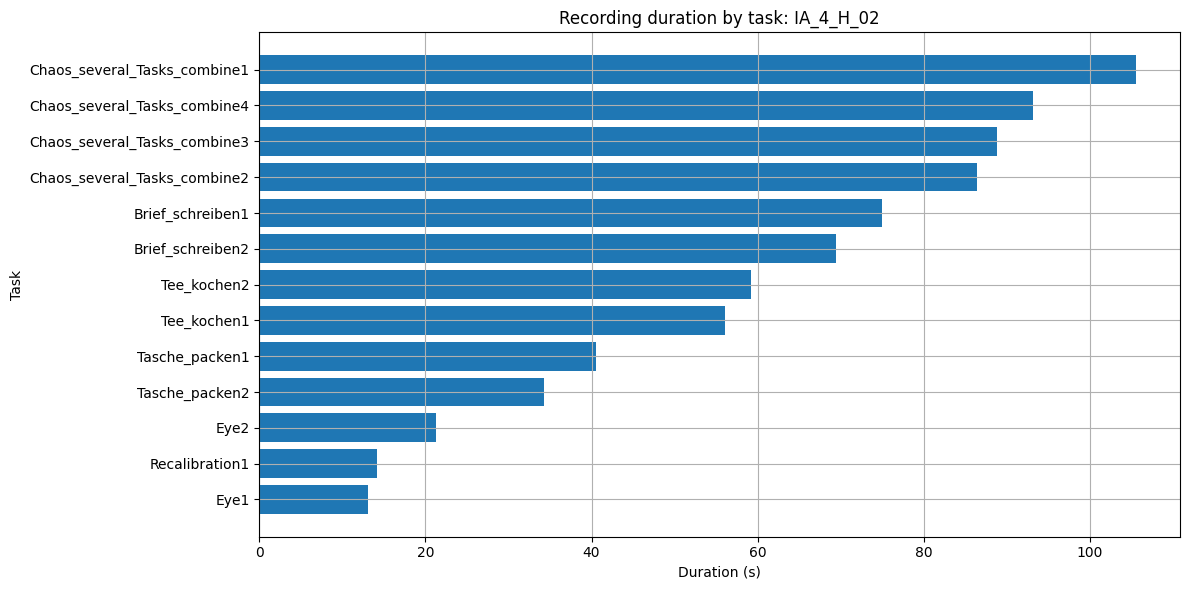

In [5]:
plot_df = summary_df.sort_values("duration_s")
plt.figure(figsize=(12, 6))
plt.barh(plot_df["task_name"], plot_df["duration_s"])
plt.xlabel("Duration (s)")
plt.ylabel("Task")
plt.title(f"Recording duration by task: {PARTICIPANT_ID}")
plt.tight_layout()

Calibration tasks such as `Eye1`, `Eye2`, and `Recalibration1` should usually be excluded from ADL feature extraction and model training.

## Selected Recording Structure

In [6]:
with h5py.File(h5_path, "r") as f:
    rows = []
    for modality_name, group in f["modalities"].items():
        keys = list(group.keys())
        first_key = keys[0] if keys else None
        length = len(group[first_key]) if first_key else 0
        rows.append({
            "modality": modality_name,
            "field_count": len(keys),
            "length": length,
            "sample_fields": ", ".join(keys[:8]),
        })

modality_df = pd.DataFrame(rows)
modality_df

,modality,field_count,length,sample_fields
0,eye_tracker__gaze,25,4861,"eyeball_center_left_x, eyeball_center_left_y, ..."
1,eye_tracker__imu,12,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
2,movella__DOT_D422CD008603,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
3,movella__DOT_D422CD008CC7,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
4,movella__DOT_D422CD009F54,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
5,movella__DOT_D422CD009F5B,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
6,movella__DOT_D422CD009F60,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
7,movella__DOT_D422CD00A220,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
8,movella__DOT_D422CD00A795,16,4861,"accel_x, accel_y, accel_z, gyro_x, gyro_y, gyr..."
9,zed__depth,5,4861,"max_depth, mean_depth, median_depth, min_depth..."


## Gaze Data

In [7]:
with h5py.File(h5_path, "r") as f:
    t = get_time_seconds(f)
    gaze_df = read_group_as_df(f, "modalities/eye_tracker__gaze")

gaze_df.head()

,eyeball_center_left_x,eyeball_center_left_y,eyeball_center_left_z,eyeball_center_right_x,eyeball_center_right_y,eyeball_center_right_z,eyelid_angle_bottom_left,eyelid_angle_bottom_right,eyelid_angle_top_left,eyelid_angle_top_right,...,optical_axis_right_x,optical_axis_right_y,optical_axis_right_z,pupil_diameter_left,pupil_diameter_right,timestamp_sensor,timestamp_system,worn,x,y
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Gaze valid ratio: 0.986
x range: (np.float32(434.72748), np.float32(1309.0673))
y range: (np.float32(488.79846), np.float32(1166.935))


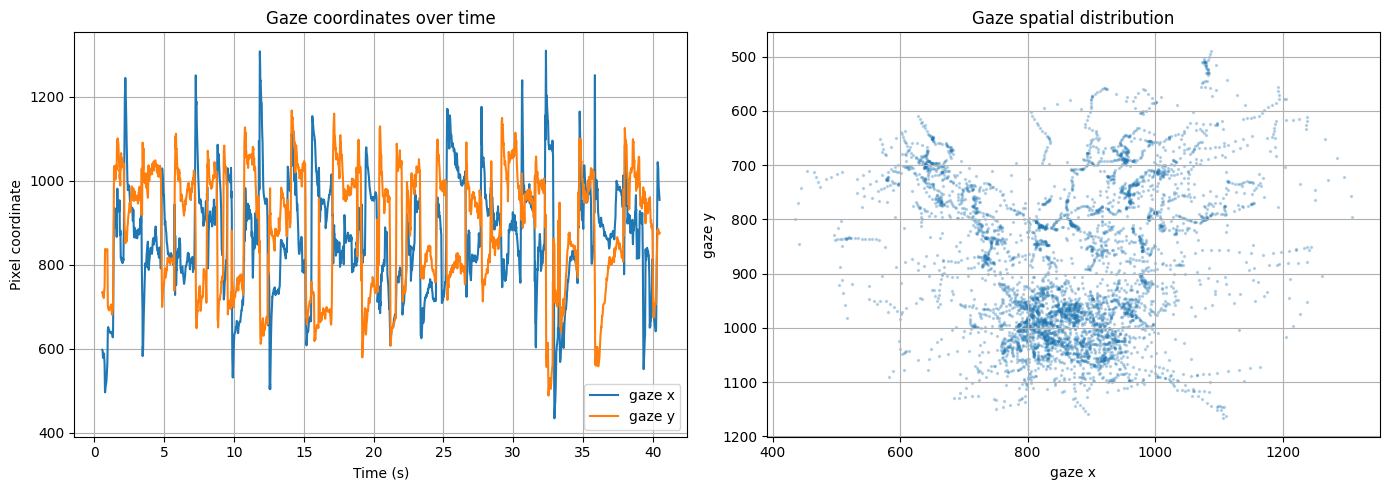

In [8]:
gaze_valid = np.isfinite(gaze_df["x"]) & np.isfinite(gaze_df["y"])
print(f"Gaze valid ratio: {gaze_valid.mean():.3f}")
print("x range:", (np.nanmin(gaze_df["x"]), np.nanmax(gaze_df["x"])))
print("y range:", (np.nanmin(gaze_df["y"]), np.nanmax(gaze_df["y"])))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(t, gaze_df["x"], label="gaze x")
axes[0].plot(t, gaze_df["y"], label="gaze y")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Pixel coordinate")
axes[0].set_title("Gaze coordinates over time")
axes[0].legend()

axes[1].scatter(gaze_df.loc[gaze_valid, "x"], gaze_df.loc[gaze_valid, "y"], s=2, alpha=0.25)
axes[1].invert_yaxis()
axes[1].set_xlabel("gaze x")
axes[1].set_ylabel("gaze y")
axes[1].set_title("Gaze spatial distribution")
plt.tight_layout()

## Skeleton and Hand Keypoints

For hand-object interaction, the key fields are usually `left/right_wrist_u/v` and hand fingertip/index fields such as `left/right_hand_index_1_u/v`.

`u/v` are 2D image coordinates. `x/y/z` are 3D coordinates from the skeleton stream.

In [9]:
with h5py.File(h5_path, "r") as f:
    skeleton_groups = [name for name in f["modalities"].keys() if name.startswith("zed__skeleton__")]

skeleton_groups

['zed__skeleton__Body_69']

In [10]:
SKELETON_GROUP = skeleton_groups[0] if skeleton_groups else None
SKELETON_GROUP

'zed__skeleton__Body_69'

In [11]:
with h5py.File(h5_path, "r") as f:
    skeleton_df = read_group_as_df(f, f"modalities/{SKELETON_GROUP}")

hand_cols = [c for c in skeleton_df.columns if "hand" in c or "wrist" in c]
print(f"Hand/wrist fields: {len(hand_cols)}")
hand_cols[:80]

Hand/wrist fields: 50


['left_hand_index_1_u',
 'left_hand_index_1_v',
 'left_hand_index_1_x',
 'left_hand_index_1_y',
 'left_hand_index_1_z',
 'left_hand_middle_4_u',
 'left_hand_middle_4_v',
 'left_hand_middle_4_x',
 'left_hand_middle_4_y',
 'left_hand_middle_4_z',
 'left_hand_pinky_1_u',
 'left_hand_pinky_1_v',
 'left_hand_pinky_1_x',
 'left_hand_pinky_1_y',
 'left_hand_pinky_1_z',
 'left_hand_thumb_4_u',
 'left_hand_thumb_4_v',
 'left_hand_thumb_4_x',
 'left_hand_thumb_4_y',
 'left_hand_thumb_4_z',
 'left_wrist_u',
 'left_wrist_v',
 'left_wrist_x',
 'left_wrist_y',
 'left_wrist_z',
 'right_hand_index_1_u',
 'right_hand_index_1_v',
 'right_hand_index_1_x',
 'right_hand_index_1_y',
 'right_hand_index_1_z',
 'right_hand_middle_4_u',
 'right_hand_middle_4_v',
 'right_hand_middle_4_x',
 'right_hand_middle_4_y',
 'right_hand_middle_4_z',
 'right_hand_pinky_1_u',
 'right_hand_pinky_1_v',
 'right_hand_pinky_1_x',
 'right_hand_pinky_1_y',
 'right_hand_pinky_1_z',
 'right_hand_thumb_4_u',
 'right_hand_thumb_4_v',


In [12]:
hand_pairs = {
    "left_wrist": ("left_wrist_u", "left_wrist_v"),
    "right_wrist": ("right_wrist_u", "right_wrist_v"),
    "left_index": ("left_hand_index_1_u", "left_hand_index_1_v"),
    "right_index": ("right_hand_index_1_u", "right_hand_index_1_v"),
}

for label, (u_col, v_col) in hand_pairs.items():
    valid = np.isfinite(skeleton_df[u_col]) & np.isfinite(skeleton_df[v_col]) & (skeleton_df[u_col] >= 0) & (skeleton_df[v_col] >= 0)
    print(label, "valid ratio", f"{valid.mean():.3f}", "u range", (skeleton_df.loc[valid, u_col].min(), skeleton_df.loc[valid, u_col].max()), "v range", (skeleton_df.loc[valid, v_col].min(), skeleton_df.loc[valid, v_col].max()))

left_wrist valid ratio 0.889 u range (np.float32(3.0780358), np.float32(689.48474)) v range (np.float32(1.2260319), np.float32(375.4374))
right_wrist valid ratio 0.951 u range (np.float32(0.8976775), np.float32(774.34753)) v range (np.float32(0.60590667), np.float32(536.9651))
left_index valid ratio 0.668 u range (np.float32(6.3939953), np.float32(713.34485)) v range (np.float32(3.2114432), np.float32(400.85907))
right_index valid ratio 0.379 u range (np.float32(1.8130339), np.float32(841.61646)) v range (np.float32(0.85320824), np.float32(599.4632))


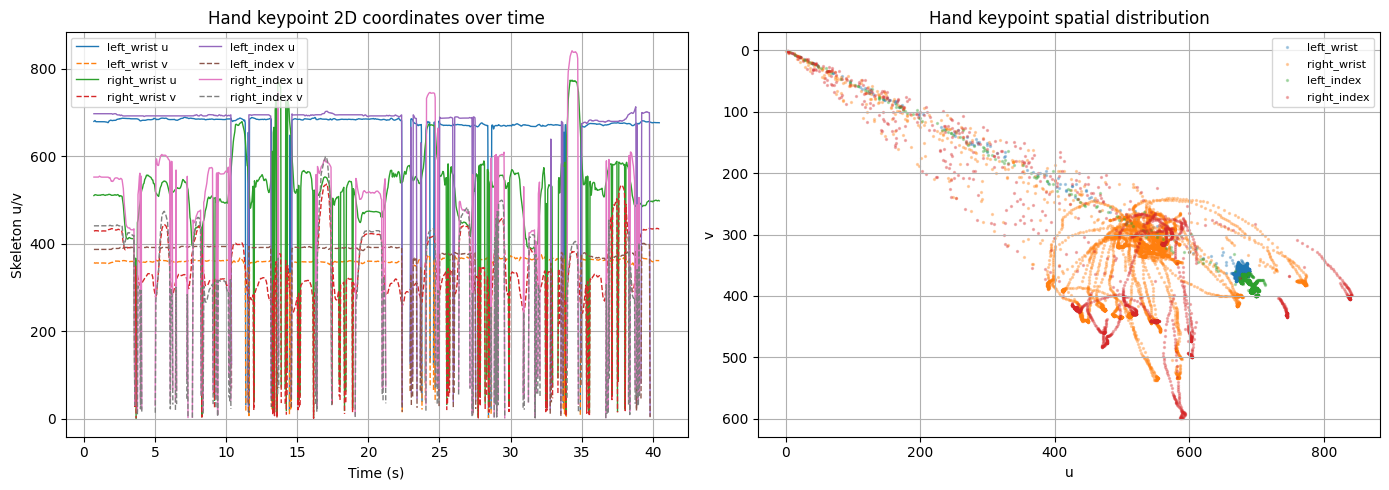

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, (u_col, v_col) in hand_pairs.items():
    valid = np.isfinite(skeleton_df[u_col]) & np.isfinite(skeleton_df[v_col]) & (skeleton_df[u_col] >= 0) & (skeleton_df[v_col] >= 0)
    axes[0].plot(t, skeleton_df[u_col].where(valid), label=f"{label} u", linewidth=1)
    axes[0].plot(t, skeleton_df[v_col].where(valid), label=f"{label} v", linewidth=1, linestyle="--")

axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Skeleton u/v")
axes[0].set_title("Hand keypoint 2D coordinates over time")
axes[0].legend(ncol=2, fontsize=8)

for label, (u_col, v_col) in hand_pairs.items():
    valid = np.isfinite(skeleton_df[u_col]) & np.isfinite(skeleton_df[v_col]) & (skeleton_df[u_col] >= 0) & (skeleton_df[v_col] >= 0)
    axes[1].scatter(skeleton_df.loc[valid, u_col], skeleton_df.loc[valid, v_col], s=2, alpha=0.3, label=label)

axes[1].invert_yaxis()
axes[1].set_xlabel("u")
axes[1].set_ylabel("v")
axes[1].set_title("Hand keypoint spatial distribution")
axes[1].legend(fontsize=8)
plt.tight_layout()

## Gaze vs Hand Coordinate Range Check

This is important before fusing with YOLO bounding boxes. If gaze, skeleton, and YOLO coordinates use different image resolutions, they must be scaled into a common coordinate system.
gaze, skeleton, and YOLO coordinates三者的坐标系对应关系 （-1值和Nan已过滤）

In [14]:
range_rows = []

gx = gaze_df["x"]
gy = gaze_df["y"]
gaze_valid = np.isfinite(gx) & np.isfinite(gy)
range_rows.append({
    "signal": "gaze",
    "x_or_u_min": gx[gaze_valid].min(),
    "x_or_u_max": gx[gaze_valid].max(),
    "y_or_v_min": gy[gaze_valid].min(),
    "y_or_v_max": gy[gaze_valid].max(),
    "valid_ratio": gaze_valid.mean(),
})

for label, (u_col, v_col) in hand_pairs.items():
    u = skeleton_df[u_col]
    v = skeleton_df[v_col]
    valid = np.isfinite(u) & np.isfinite(v) & (u >= 0) & (v >= 0)
    range_rows.append({
        "signal": label,
        "x_or_u_min": u[valid].min(),
        "x_or_u_max": u[valid].max(),
        "y_or_v_min": v[valid].min(),
        "y_or_v_max": v[valid].max(),
        "valid_ratio": valid.mean(),
    })

pd.DataFrame(range_rows)

,signal,x_or_u_min,x_or_u_max,y_or_v_min,y_or_v_max,valid_ratio
0,gaze,434.727478,1309.067261,488.798462,1166.935059,0.986011
1,left_wrist,3.078036,689.484741,1.226032,375.437408,0.888706
2,right_wrist,0.897677,774.347534,0.605907,536.965088,0.951450
3,left_index,6.393995,713.344849,3.211443,400.859070,0.667558
4,right_index,1.813034,841.616455,0.853208,599.463196,0.378523


## IMU Signals

In [15]:
with h5py.File(h5_path, "r") as f:
    imu_groups = [name for name in f["modalities"].keys() if name.startswith("movella__")]

imu_groups

['movella__DOT_D422CD008603',
 'movella__DOT_D422CD008CC7',
 'movella__DOT_D422CD009F54',
 'movella__DOT_D422CD009F5B',
 'movella__DOT_D422CD009F60',
 'movella__DOT_D422CD00A220',
 'movella__DOT_D422CD00A795']

In [16]:
IMU_GROUP = imu_groups[0]

with h5py.File(h5_path, "r") as f:
    imu_df = read_group_as_df(f, f"modalities/{IMU_GROUP}")

imu_df.head()

,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,pitch,quat_w,quat_x,quat_y,quat_z,roll,seq_id,timestamp_sensor,timestamp_system,yaw
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


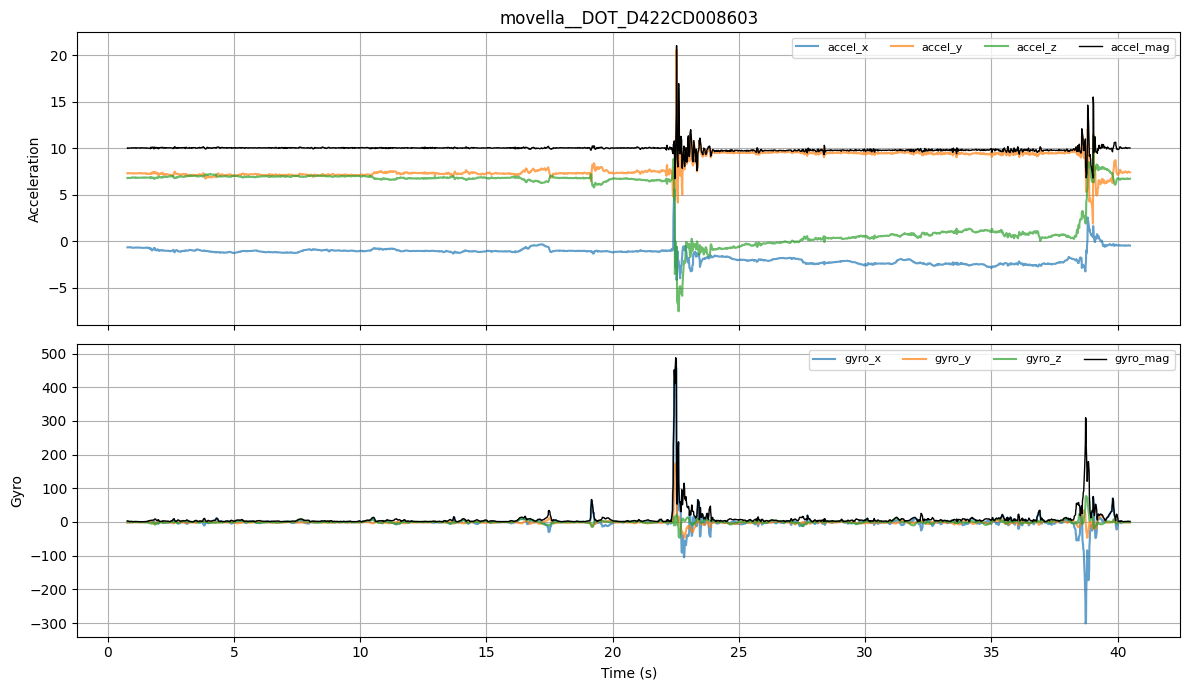

In [17]:
acc_mag = np.sqrt(imu_df["accel_x"]**2 + imu_df["accel_y"]**2 + imu_df["accel_z"]**2)
gyro_mag = np.sqrt(imu_df["gyro_x"]**2 + imu_df["gyro_y"]**2 + imu_df["gyro_z"]**2)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(t, imu_df["accel_x"], label="accel_x", alpha=0.7)
axes[0].plot(t, imu_df["accel_y"], label="accel_y", alpha=0.7)
axes[0].plot(t, imu_df["accel_z"], label="accel_z", alpha=0.7)
axes[0].plot(t, acc_mag, label="accel_mag", color="black", linewidth=1)
axes[0].set_ylabel("Acceleration")
axes[0].set_title(IMU_GROUP)
axes[0].legend(ncol=4, fontsize=8)

axes[1].plot(t, imu_df["gyro_x"], label="gyro_x", alpha=0.7)
axes[1].plot(t, imu_df["gyro_y"], label="gyro_y", alpha=0.7)
axes[1].plot(t, imu_df["gyro_z"], label="gyro_z", alpha=0.7)
axes[1].plot(t, gyro_mag, label="gyro_mag", color="black", linewidth=1)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Gyro")
axes[1].legend(ncol=4, fontsize=8)
plt.tight_layout()

## Depth Summary

In [18]:
with h5py.File(h5_path, "r") as f:
    depth_df = read_group_as_df(f, "modalities/zed__depth") if "zed__depth" in f["modalities"] else None

depth_df.head() if depth_df is not None else "No zed__depth group"

,max_depth,mean_depth,median_depth,min_depth,valid_ratio
0,4469.000000,2515.133545,2376.0,1159.000000,0.985686
1,4468.981445,2515.123291,2376.0,1158.981689,0.985686
2,4468.963379,2515.113281,2376.0,1158.963257,0.985687
3,4468.944824,2515.103271,2376.0,1158.944946,0.985687
4,4468.926758,2515.093262,2376.0,1158.926636,0.985688


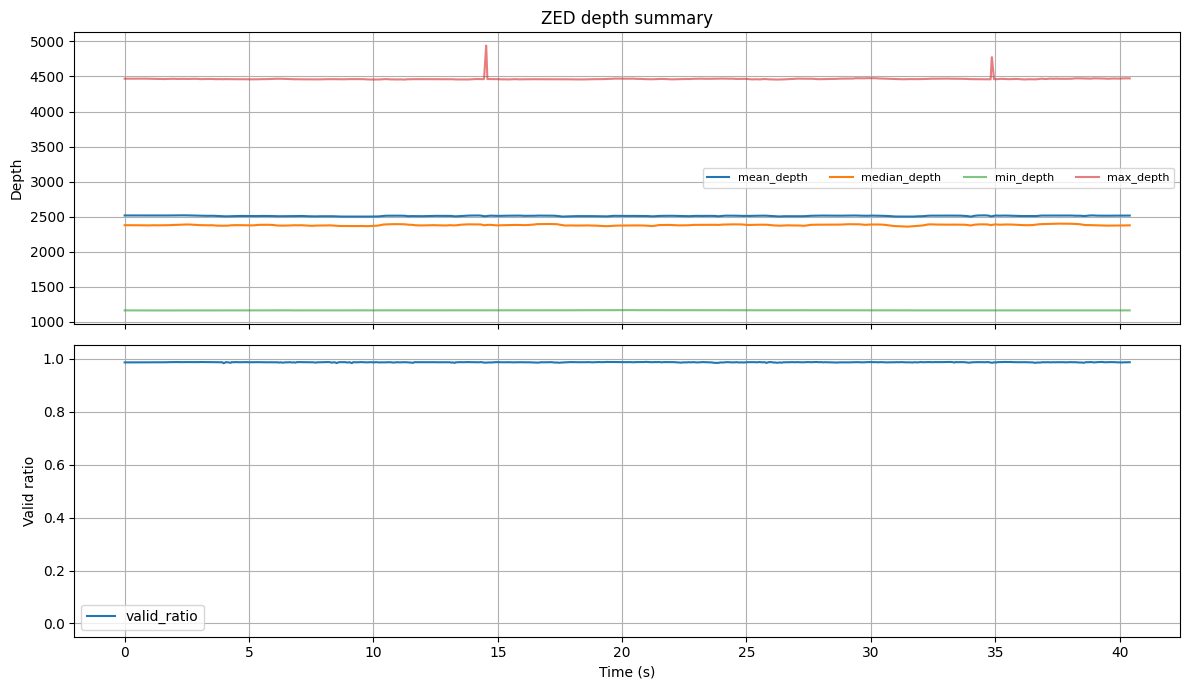

In [19]:
if depth_df is not None:
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(t, depth_df["mean_depth"], label="mean_depth")
    axes[0].plot(t, depth_df["median_depth"], label="median_depth")
    axes[0].plot(t, depth_df["min_depth"], label="min_depth", alpha=0.6)
    axes[0].plot(t, depth_df["max_depth"], label="max_depth", alpha=0.6)
    axes[0].set_ylabel("Depth")
    axes[0].legend(ncol=4, fontsize=8)
    axes[0].set_title("ZED depth summary")

    axes[1].plot(t, depth_df["valid_ratio"], label="valid_ratio")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Valid ratio")
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].legend()
    plt.tight_layout()

## Missingness Overview

In [20]:
missing_rows = []

with h5py.File(h5_path, "r") as f:
    for modality_name, group in f["modalities"].items():
        for field_name, dataset in group.items():
            values = dataset[:]
            if np.issubdtype(values.dtype, np.number):
                missing_rows.append({
                    "modality": modality_name,
                    "field": field_name,
                    "finite_ratio": finite_ratio(values),
                    "nan_count": int(np.isnan(values).sum()) if np.issubdtype(values.dtype, np.floating) else 0,
                })

missing_df = pd.DataFrame(missing_rows)
missing_summary = (
    missing_df.groupby("modality", as_index=False)
    .agg(mean_finite_ratio=("finite_ratio", "mean"), min_finite_ratio=("finite_ratio", "min"), field_count=("field", "count"))
    .sort_values("mean_finite_ratio")
)
missing_summary

,modality,mean_finite_ratio,min_finite_ratio,field_count
10,zed__skeleton__Body_69,0.818495,0.000000,185
4,movella__DOT_D422CD009F54,0.975314,0.975314,16
8,movella__DOT_D422CD00A795,0.975314,0.975314,16
2,movella__DOT_D422CD008603,0.980457,0.980457,16
5,movella__DOT_D422CD009F5B,0.981280,0.981280,16
0,eye_tracker__gaze,0.986011,0.986011,25
6,movella__DOT_D422CD009F60,0.986217,0.986217,16
7,movella__DOT_D422CD00A220,0.988274,0.988274,16
3,movella__DOT_D422CD008CC7,0.995063,0.995063,16
1,eye_tracker__imu,0.997737,0.997737,12


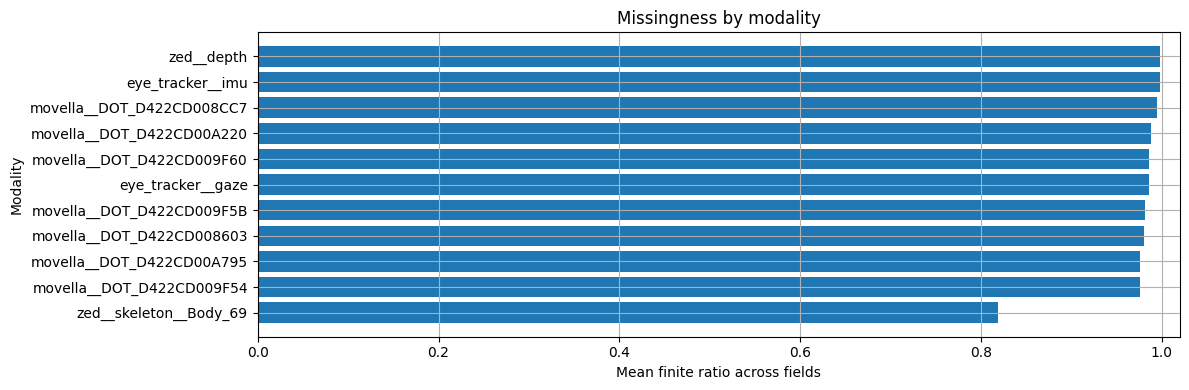

In [21]:
plt.figure(figsize=(12, max(4, 0.35 * len(missing_summary))))
plt.barh(missing_summary["modality"], missing_summary["mean_finite_ratio"])
plt.xlabel("Mean finite ratio across fields")
plt.ylabel("Modality")
plt.title("Missingness by modality")
plt.xlim(0, 1.02)
plt.tight_layout()

## Dataset-Wide Missingness Detail Table

Scan every non-calibration aligned H5 recording and list missingness for each participant, task, modality, and numeric field. The special `eye_tracker__gaze/gaze_xy` row treats gaze `x` and `y` as one coordinate pair: it is valid only when both are finite.


In [22]:
SKIP_TASKS = {"Eye1", "Eye2", "Recalibration1"}


def participant_from_h5(path):
    return path.parent.name


def full_id_from_h5(path):
    return path.stem.replace("_aligned_dataset", "")


def numeric_missingness(values):
    values = np.asarray(values)
    row_count = int(values.size)
    if row_count == 0:
        return 0, 0, np.nan

    valid_count = int(np.isfinite(values).sum())
    missing_count = row_count - valid_count
    missing_ratio = missing_count / row_count
    return valid_count, missing_count, missing_ratio


def scan_recording_missingness(path):
    participant_id = participant_from_h5(path)
    task_name = task_from_h5(path)
    full_id = full_id_from_h5(path)
    rows = []

    with h5py.File(path, "r") as f:
        for modality_name, group in f["modalities"].items():
            if modality_name == "eye_tracker__gaze" and "x" in group and "y" in group:
                x = group["x"][:]
                y = group["y"][:]
                valid_xy = np.isfinite(x) & np.isfinite(y)
                row_count = int(len(valid_xy))
                valid_count = int(valid_xy.sum())
                missing_count = row_count - valid_count
                rows.append({
                    "participant_id": participant_id,
                    "task_name": task_name,
                    "full_id": full_id,
                    "modality": modality_name,
                    "field": "gaze_xy",
                    "row_count": row_count,
                    "valid_count": valid_count,
                    "missing_count": missing_count,
                    "missing_ratio": missing_count / row_count if row_count else np.nan,
                    "path": path,
                })

            for field_name, dataset in group.items():
                values = dataset[:]
                if not np.issubdtype(values.dtype, np.number):
                    continue

                valid_count, missing_count, missing_ratio = numeric_missingness(values)
                rows.append({
                    "participant_id": participant_id,
                    "task_name": task_name,
                    "full_id": full_id,
                    "modality": modality_name,
                    "field": field_name,
                    "row_count": int(np.asarray(values).size),
                    "valid_count": valid_count,
                    "missing_count": missing_count,
                    "missing_ratio": missing_ratio,
                    "path": path,
                })

    return rows


all_h5_files = sorted(ALIGNED_H5_ROOT.glob("*/*.h5"))
adl_h5_files = [p for p in all_h5_files if task_from_h5(p) not in SKIP_TASKS]

missingness_rows = []
for path in adl_h5_files:
    missingness_rows.extend(scan_recording_missingness(path))

missingness_detail_df = pd.DataFrame(missingness_rows)
missingness_detail_df = missingness_detail_df.sort_values([
    "participant_id",
    "task_name",
    "modality",
    "field",
]).reset_index(drop=True)

missingness_detail_df[[
    "participant_id",
    "task_name",
    "full_id",
    "modality",
    "field",
    "row_count",
    "valid_count",
    "missing_count",
    "missing_ratio",
]]


,participant_id,task_name,full_id,modality,field,row_count,valid_count,missing_count,missing_ratio
0,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,eye_tracker__gaze,eyeball_center_left_x,8993,8945,48,0.005337
1,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,eye_tracker__gaze,eyeball_center_left_y,8993,8945,48,0.005337
2,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,eye_tracker__gaze,eyeball_center_left_z,8993,8945,48,0.005337
3,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,eye_tracker__gaze,eyeball_center_right_x,8993,8945,48,0.005337
4,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,eye_tracker__gaze,eyeball_center_right_y,8993,8945,48,0.005337
...,...,...,...,...,...,...,...,...,...
77215,IA_4_H_14,Teekochen2,IA_4_H_14_Teekochen2,zed__skeleton__Body_283,spine_3_u,8309,8259,50,0.006018
77216,IA_4_H_14,Teekochen2,IA_4_H_14_Teekochen2,zed__skeleton__Body_283,spine_3_v,8309,8259,50,0.006018
77217,IA_4_H_14,Teekochen2,IA_4_H_14_Teekochen2,zed__skeleton__Body_283,spine_3_x,8309,8259,50,0.006018
77218,IA_4_H_14,Teekochen2,IA_4_H_14_Teekochen2,zed__skeleton__Body_283,spine_3_y,8309,8259,50,0.006018


In [23]:
pd.set_option("display.max_rows", 300)

high_missing_detail_df = (
    missingness_detail_df[missingness_detail_df["missing_ratio"] >= 0.95]
    .sort_values(["missing_ratio", "participant_id", "task_name", "modality", "field"], ascending=[False, True, True, True, True])
    .reset_index(drop=True)
)

high_missing_detail_df[[
    "participant_id",
    "task_name",
    "full_id",
    "modality",
    "field",
    "row_count",
    "valid_count",
    "missing_count",
    "missing_ratio",
]]


,participant_id,task_name,full_id,modality,field,row_count,valid_count,missing_count,missing_ratio
0,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,zed__skeleton__Body_137,left_ankle_x,8993,0,8993,1.000000
1,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,zed__skeleton__Body_137,left_ankle_y,8993,0,8993,1.000000
2,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,zed__skeleton__Body_137,left_ankle_z,8993,0,8993,1.000000
3,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,zed__skeleton__Body_137,left_big_toe_x,8993,0,8993,1.000000
4,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,zed__skeleton__Body_137,left_big_toe_y,8993,0,8993,1.000000
...,...,...,...,...,...,...,...,...,...
42142,IA_4_H_04,Chaos_several_Tasks_combine3,IA_4_H_04_Chaos_several_Tasks_combine3,zed__skeleton__Body_75,left_hand_index_1_y,10815,533,10282,0.950717
42143,IA_4_H_04,Chaos_several_Tasks_combine3,IA_4_H_04_Chaos_several_Tasks_combine3,zed__skeleton__Body_75,left_hand_index_1_z,10815,533,10282,0.950717
42144,IA_4_H_05,Brief_schreiben1,IA_4_H_05_Brief_schreiben1,zed__skeleton__Body_133,left_hand_middle_4_x,7650,381,7269,0.950196
42145,IA_4_H_05,Brief_schreiben1,IA_4_H_05_Brief_schreiben1,zed__skeleton__Body_133,left_hand_middle_4_y,7650,381,7269,0.950196


## Notes for Object Interaction Features

- Gaze-object interaction can use `eye_tracker__gaze/x,y` and YOLO bbox coordinates if both are in the same world-camera pixel coordinate system.
- Hand-object interaction can use skeleton hand keypoints such as `left/right_wrist_u,v` or `left/right_hand_index_1_u,v`.
- Before combining skeleton `u/v` with YOLO bbox coordinates, verify coordinate scale and camera alignment. In the inspected sample, gaze and skeleton coordinate ranges appear different, so scaling/calibration may be required.
- Treat `-1` and `NaN` skeleton coordinates as invalid.
- For recordings with multiple `zed__skeleton__Body_*` groups, select the main body track before extracting hand-object features.